Week 1 notebook, polynomial and interaction terms, Mike Hembree

Same project as the other weeks. The capstone is an early warning model for ICU delirium on MIMIC-IV, and everything here runs on the MIMIC-IV Clinical Database Demo (100 patients, 140 ICU stays) because the full credentialed database access is still pending. The feature table is the same one from Week 2 and Week 4, vitals, demographics, total GCS, and a flag for a positive CAM-ICU delirium screen. Polynomial and interaction terms need a continuous target to make the story easy to read, so like Week 2 the target here is ICU length of stay in days.

In [1]:
# imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
from sklearn.model_selection import train_test_split, RepeatedKFold, RepeatedStratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error, roc_auc_score, roc_curve, f1_score, recall_score, precision_score, accuracy_score, confusion_matrix

warnings.filterwarnings('ignore')
plt.rcParams['figure.dpi'] = 110
plt.rcParams['font.family'] = 'serif'


In [2]:
# load the feature table and fill the few missing values with the median
feat = pd.read_csv('delirium_features.csv')

rcols = ['anchor_age', 'gender', 'heart_rate', 'sbp', 'dbp', 'resp_rate', 'temp_f', 'spo2', 'gcs_total_min', 'delirium_positive']
ccols = rcols[:-1]

data = feat[rcols + ['los']].copy()
for c in rcols:
    data[c] = data[c].fillna(data[c].median())

X = data[rcols]
y = data['los']
Xc = data[ccols]
yc = feat['delirium_positive'].fillna(0).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size = 0.2, random_state = 42)
Xc_train, Xc_test, yc_train, yc_test = train_test_split(Xc, yc, test_size = 0.2, random_state = 42, stratify = yc)

cv_reg = RepeatedKFold(n_splits = 5, n_repeats = 6, random_state = 1)
cv_clf = RepeatedStratifiedKFold(n_splits = 5, n_repeats = 3, random_state = 1)
print(data.shape, yc.value_counts().to_dict())


(140, 11) {0: 95, 1: 45}


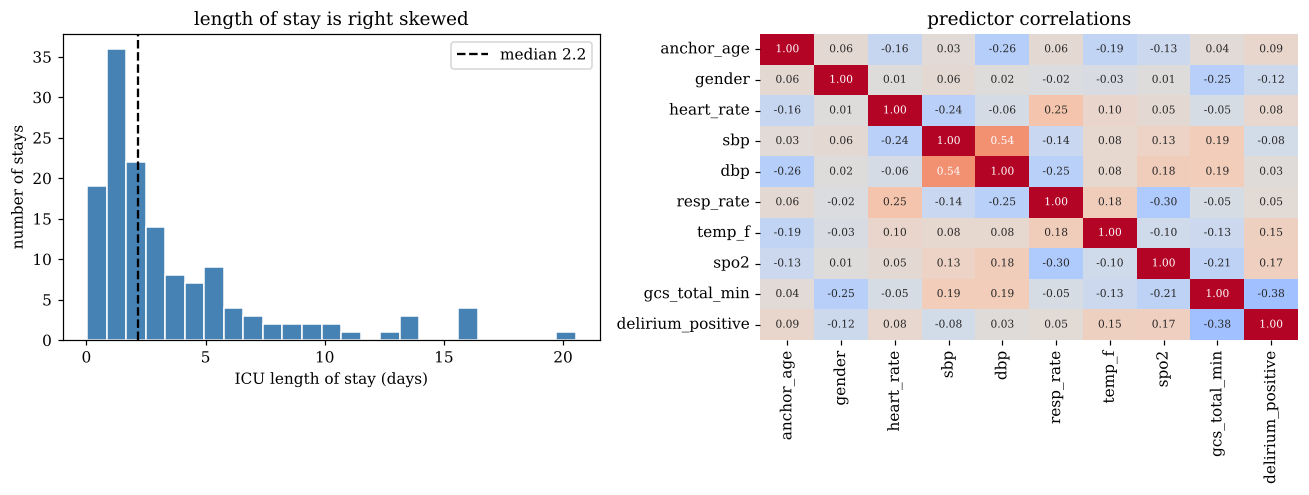

count    140.000000
mean       3.679379
std        3.896354
min        0.023727
25%        1.170663
50%        2.155093
75%        4.907749
max       20.528681
Name: los, dtype: float64
positive delirium rate: 0.321
gcs_total_min       -0.424115
sbp                 -0.205243
dbp                 -0.108665
gender              -0.009690
anchor_age           0.006159
spo2                 0.056744
resp_rate            0.100994
heart_rate           0.170771
temp_f               0.195557
delirium_positive    0.540592
los                  1.000000
Name: los, dtype: float64


In [3]:
# eda, length of stay distribution and predictor correlations
fig, ax = plt.subplots(1, 2, figsize = (12, 4.6))
ax[0].hist(data['los'], bins = 25, color = 'steelblue', edgecolor = 'white')
ax[0].axvline(data['los'].median(), color = 'black', linestyle = '--', label = 'median ' + str(round(data['los'].median(), 1)))
ax[0].set_xlabel('ICU length of stay (days)')
ax[0].set_ylabel('number of stays')
ax[0].set_title('length of stay is right skewed')
ax[0].legend()
sns.heatmap(data[rcols].corr(), annot = True, fmt = '.2f', cmap = 'coolwarm', center = 0, ax = ax[1], annot_kws = {'size': 7}, cbar = False)
ax[1].set_title('predictor correlations')
plt.tight_layout()
plt.savefig('figs/eda.png', dpi = 200)
plt.show()
print(data['los'].describe())
print('positive delirium rate:', round(yc.mean(), 3))
print(data[rcols + ['los']].corr()['los'].sort_values())


Length of stay is heavily right skewed, median 2.2 days but a mean of 3.7 and a max over 20, so a handful of long stays are going to pull on any least squares fit. Delirium has the strongest correlation with length of stay (0.54) and gcs_total_min comes next (negative 0.42). Among the predictors the only strong pair is sbp and dbp at 0.54, and gcs_total_min and delirium_positive sit at negative 0.38. Nothing is crazy collinear, which is part of why I expected the plain linear model to hold up.

In [4]:
# holdout comparison, linear vs interaction terms vs full degree 2
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures

def holdout(name, model):
    model.fit(X_train, y_train)
    tr = r2_score(y_train, model.predict(X_train))
    te = r2_score(y_test, model.predict(X_test))
    rm = mean_squared_error(y_test, model.predict(X_test)) ** 0.5
    return {'model': name, 'train r2': tr, 'test r2': te, 'test rmse': rm}

models = {
    'linear': make_pipeline(StandardScaler(), LinearRegression()),
    'interactions only': make_pipeline(StandardScaler(), PolynomialFeatures(2, interaction_only = True, include_bias = False), LinearRegression()),
    'degree 2': make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias = False), LinearRegression()),
}
pd.DataFrame([holdout(k, m) for k, m in models.items()])


,model,train r2,test r2,test rmse
0,linear,0.384964,0.338080,3.131483
1,interactions only,0.750277,-0.540411,4.777114
2,degree 2,0.772927,-0.471702,4.669359


In [5]:
# how many columns each expansion creates
for k in [1, 2]:
    print('degree', k, 'full:', PolynomialFeatures(k, include_bias = False).fit(X_train).n_output_features_)
print('interactions only:', PolynomialFeatures(2, interaction_only = True, include_bias = False).fit(X_train).n_output_features_)
print('training rows:', len(X_train))


degree 1 full: 10
degree 2 full: 65
interactions only: 55
training rows: 112


This is the thing to watch. Degree 2 turns 10 columns into 65 and interactions only gives 55, and the training split only has 112 rows. On the holdout split the linear model scores a test r squared of 0.34 while interactions only and degree 2 both go negative (about negative 0.54 and negative 0.47), even though their training r squared jumps to 0.75 and 0.77. Negative test r squared means worse than just predicting the average stay. The repeated cross validation table below tells the same story with less luck involved, linear sits at a cv r squared of 0.15, interactions only at negative 1.06 and degree 2 at negative 3.62. Adding a ridge penalty on top of degree 2 pulls it back to about zero but still doesn't beat the linear model.

In [6]:
# repeated cross validation on all 140 stays, train r2 against validation r2
from sklearn.linear_model import RidgeCV

cv_models = dict(models)
cv_models['degree 2 plus ridge'] = make_pipeline(StandardScaler(), PolynomialFeatures(2, include_bias = False), StandardScaler(), RidgeCV(alphas = np.logspace(-1, 4, 40)))

rows = []
for name, m in cv_models.items():
    r = cross_validate(m, X, y, cv = cv_reg, scoring = ('r2', 'neg_root_mean_squared_error'), return_train_score = True, n_jobs = 2)
    rows.append({'model': name, 'train r2': r['train_r2'].mean(), 'cv r2': r['test_r2'].mean(), 'cv rmse': -r['test_neg_root_mean_squared_error'].mean(), 'cv rmse sd': r['test_neg_root_mean_squared_error'].std()})
poly_res = pd.DataFrame(rows)
poly_res.to_csv('figs/poly_results.csv', index = False)
poly_res


,model,train r2,cv r2,cv rmse,cv rmse sd
0,linear,0.398982,0.151098,3.350120,0.748038
1,interactions only,0.782609,-1.058669,4.624501,1.162709
2,degree 2,0.813000,-3.622194,6.036234,3.079681
3,degree 2 plus ridge,0.605381,-0.023799,3.528632,0.980977


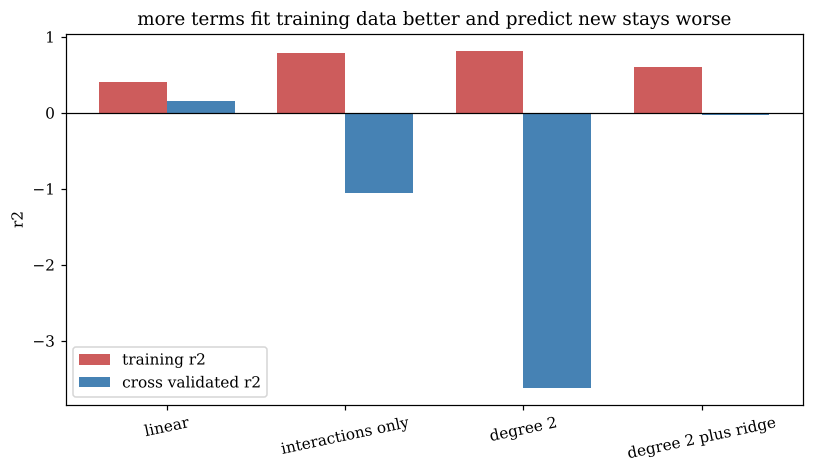

In [7]:
# figure, train r2 against cv r2
fig, ax = plt.subplots(figsize = (7.5, 4.4))
w = 0.38
pos = np.arange(len(poly_res))
ax.bar(pos - w / 2, poly_res['train r2'], w, label = 'training r2', color = 'indianred')
ax.bar(pos + w / 2, poly_res['cv r2'], w, label = 'cross validated r2', color = 'steelblue')
ax.axhline(0, color = 'black', linewidth = 0.8)
ax.set_xticks(pos)
ax.set_xticklabels(poly_res['model'], rotation = 12)
ax.set_ylabel('r2')
ax.set_title('more terms fit training data better and predict new stays worse')
ax.legend()
plt.tight_layout()
plt.savefig('figs/poly.png', dpi = 200)
plt.show()


So for this dataset polynomial and interaction terms were a clear net negative. The extra terms mostly fit noise in 112 training rows. If I tried this again I'd only expand two or three variables I had a reason to expect interact, like gcs_total_min and delirium_positive, instead of expanding all ten.